# 04 - Loan Approval Prediction
**Topic:** Classification  |  **Reference:** "Loan Approval Prediction using Python" (amanxai.com, May 2023)

**Question.** From an applicant's profile, will the loan be approved? (Historical decisions of one housing-finance company.)

**Reference method:** fill missing values, one random 80/20 split, `StandardScaler` + random forest, report one accuracy.
**What I do differently:** data sets this small (491 labelled rows) make a single split's accuracy very noisy, so I (1) put preparation inside a pipeline so it cannot leak, (2) score with repeated cross-validation and show the spread, (3) compare against two trivial baselines, (4) check calibration and the cost of a wrong approval, and (5) look at how decisions differ between applicant groups.

**Data note.** The reference uses 614 rows; the public copy I could download has labels for **491** of them (the other 123 are an unlabelled test file). Numbers are therefore not directly comparable with the article.

## 1. Libraries and data

In [1]:
import warnings, os, json, joblib
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold, cross_validate, cross_val_predict, train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline, Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.calibration import calibration_curve
from sklearn.metrics import accuracy_score, roc_auc_score, f1_score, confusion_matrix, brier_score_loss
sns.set_theme(style="whitegrid", context="notebook")
os.makedirs("model", exist_ok=True)
df = pd.read_csv("../_data/loan_train.csv").drop(columns=["Unnamed: 0", "Loan_ID"], errors="ignore")
df = df.loc[:, ~df.columns.str.startswith("Unnamed")]
print(df.shape); df.head()

(491, 12)


,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,Female,No,0,Graduate,No,4547,0.0,115.0,360.0,1.0,Semiurban,1
1,Male,Yes,3+,Not Graduate,Yes,5703,0.0,130.0,360.0,1.0,Rural,1
2,Female,Yes,0,Graduate,No,4333,2451.0,110.0,360.0,1.0,Urban,0
3,Male,Yes,0,Not Graduate,Yes,4695,0.0,96.0,NaN,1.0,Urban,1
4,Male,Yes,2,Graduate,No,6700,1750.0,230.0,300.0,1.0,Semiurban,1


## 2. Look at the data first

In [2]:
print("approval rate: %.1f%%  (class 1 = approved)" % (df.Loan_Status.mean() * 100))
miss = df.isna().sum(); print("\nmissing values:\n", miss[miss > 0].to_string())
print("\ncategories:", {c: df[c].dropna().unique().tolist() for c in ["Gender", "Married", "Dependents", "Education", "Self_Employed", "Property_Area", "Credit_History"]})
print(df[["ApplicantIncome", "CoapplicantIncome", "LoanAmount", "Loan_Amount_Term"]].describe().round(0).T.to_string())

approval rate: 69.9%  (class 1 = approved)

missing values:
 Gender              10
Married              1
Dependents           9
Self_Employed       29
LoanAmount          16
Loan_Amount_Term    13
Credit_History      43

categories: {'Gender': ['Female', 'Male'], 'Married': ['No', 'Yes'], 'Dependents': ['0', '3+', '2', '1'], 'Education': ['Graduate', 'Not Graduate'], 'Self_Employed': ['No', 'Yes'], 'Property_Area': ['Semiurban', 'Rural', 'Urban'], 'Credit_History': [1.0, 0.0]}
                   count    mean     std    min     25%     50%     75%      max
ApplicantIncome    491.0  5401.0  6419.0  150.0  2924.0  3865.0  5706.0  81000.0
CoapplicantIncome  491.0  1590.0  2919.0    0.0     0.0  1229.0  2252.0  41667.0
LoanAmount         475.0   145.0    86.0   17.0   100.0   126.0   162.0    700.0
Loan_Amount_Term   478.0   341.0    67.0   12.0   360.0   360.0   360.0    480.0


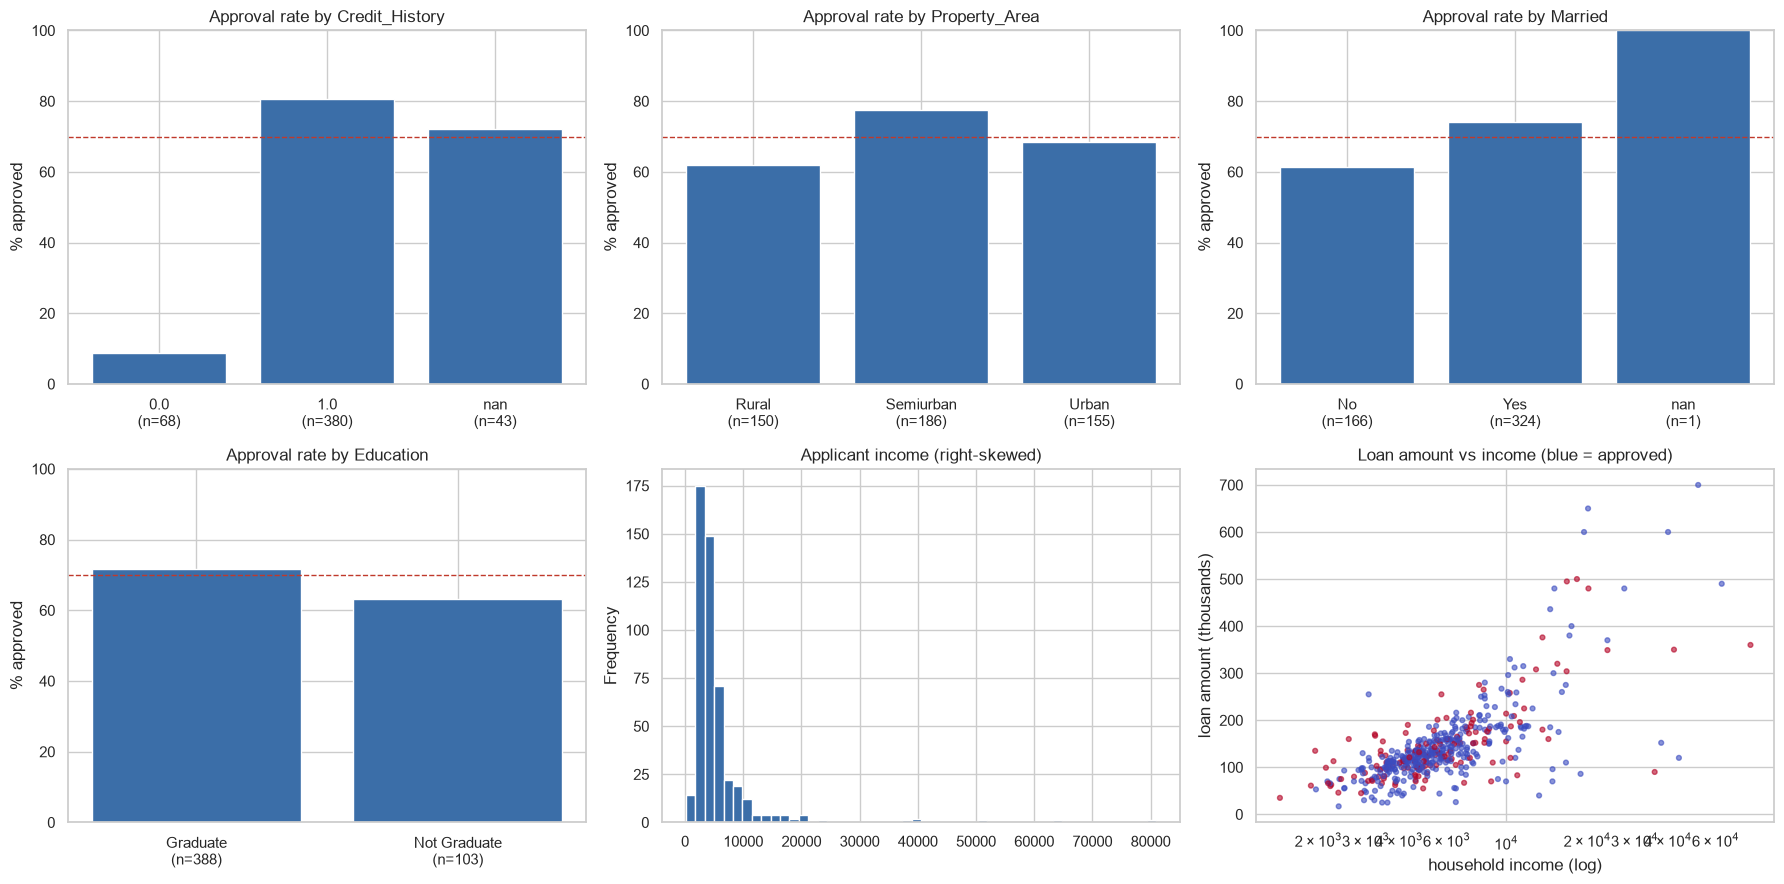

In [3]:
fig, ax = plt.subplots(2, 3, figsize=(18, 9))
for a, c in zip(ax.ravel()[:4], ["Credit_History", "Property_Area", "Married", "Education"]):
    g = df.groupby(c, dropna=False)["Loan_Status"].agg(["mean", "size"]); labs = [f"{k}\n(n={n})" for k, n in zip(g.index, g["size"])]
    a.bar(labs, g["mean"].to_numpy() * 100, color="#3b6ea8"); a.set_ylim(0, 100); a.set_ylabel("% approved"); a.set_title(f"Approval rate by {c}")
    a.axhline(df.Loan_Status.mean() * 100, color="#c0392b", ls="--", lw=1)
df.ApplicantIncome.plot.hist(bins=50, ax=ax[1, 1], color="#3b6ea8"); ax[1, 1].set_title("Applicant income (right-skewed)")
ax[1, 2].scatter(df.ApplicantIncome + df.CoapplicantIncome, df.LoanAmount, c=df.Loan_Status, cmap="coolwarm_r", s=12, alpha=.6); ax[1, 2].set_xscale("log")
ax[1, 2].set_xlabel("household income (log)"); ax[1, 2].set_ylabel("loan amount (thousands)"); ax[1, 2].set_title("Loan amount vs income (blue = approved)")
plt.tight_layout(); plt.show()

**Reading it.**
* 69.9% of applications were approved, so "approve everyone" is already 70% accurate: any model must beat that.
* **Credit history dominates:** applicants with a credit history of 0 were approved 8.8% of the time (68 people), those with 1 were approved 80.5% (380 people), and 43 people with the field missing 72.1%. Property area matters less (rural 62%, urban 68%, semi-urban 77%).
* Missing data is modest: `Credit_History` is the largest gap (43 of 491 rows), then `Self_Employed` (29) and `LoanAmount` (16). Incomes are strongly right-skewed (median about 3,900, maximum 81,000), hence the log features.
* These are associations in past decisions; they describe what the lender did, not who would repay.

## 3. Preparation inside a pipeline
Missing values are filled **inside each cross-validation fold** (median for numbers, most frequent for categories), so no information from validation rows reaches the fitting step. Extra features: total income, loan amount relative to income, an instalment estimate (`LoanAmount*1000 / term`), and log versions of the skewed money columns.

In [4]:
def add_feats(x):
    x = x.copy()
    x["TotalIncome"] = x.ApplicantIncome + x.CoapplicantIncome
    x["LogTotalIncome"] = np.log1p(x.TotalIncome)
    x["LogLoan"] = np.log1p(x.LoanAmount)
    x["EMI"] = x.LoanAmount * 1000 / x.Loan_Amount_Term
    x["EMI_to_income"] = x.EMI / x.TotalIncome.replace(0, np.nan)
    return x
num = ["ApplicantIncome", "CoapplicantIncome", "LoanAmount", "Loan_Amount_Term", "LogTotalIncome", "LogLoan", "EMI", "EMI_to_income"]
cat = ["Gender", "Married", "Dependents", "Education", "Self_Employed", "Property_Area", "Credit_History"]
X = df.drop(columns="Loan_Status"); y = df.Loan_Status.astype(int)
X["Credit_History"] = X["Credit_History"].astype("object")
def prep(scale):
    return ColumnTransformer([("n", make_pipeline(SimpleImputer(strategy="median"), StandardScaler() if scale else "passthrough"), num),
                              ("c", make_pipeline(SimpleImputer(strategy="most_frequent"), OneHotEncoder(handle_unknown="ignore")), cat)])
fe = FunctionTransformer(add_feats)
class CreditRule(ClassifierMixin, BaseEstimator):
    '''no learning: approve if Credit_History == 1, reject otherwise (missing counts as 1)'''
    def fit(self, X, y): self.classes_ = np.array([0, 1]); return self
    def predict_proba(self, X):
        p = (X["Credit_History"].astype(float).fillna(1) == 1).astype(float).to_numpy(); return np.c_[1 - p, p]
    def predict(self, X): return self.predict_proba(X)[:, 1].round().astype(int)
print("features after engineering:", len(num), "numeric +", len(cat), "categorical")

features after engineering: 8 numeric + 7 categorical


## 4. Models, scored with 5-fold CV repeated 10 times (50 fits per model)
Baselines: **majority class** (approve everybody) and a **one-line credit-history rule**. Then logistic regression, random forest (the reference's model) and gradient boosting.

In [5]:
models = {
 "approve everyone": Pipeline([("fe", fe), ("m", DummyClassifier(strategy="most_frequent"))]),
 "rule: credit history = 1": Pipeline([("fe", fe), ("m", CreditRule())]),
 "logistic regression": Pipeline([("fe", fe), ("p", prep(True)), ("m", LogisticRegression(C=0.5, max_iter=2000))]),
 "random forest": Pipeline([("fe", fe), ("p", prep(False)), ("m", RandomForestClassifier(500, min_samples_leaf=5, max_features="sqrt", random_state=0, n_jobs=-1))]),
 "gradient boosting": Pipeline([("fe", fe), ("p", prep(False)), ("m", HistGradientBoostingClassifier(learning_rate=.04, max_iter=150, max_depth=3, min_samples_leaf=15, l2_regularization=2.0, random_state=0))]),
}
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=0)
rows, folds = [], {}
for name, m in models.items():
    r = cross_validate(m, X, y, cv=cv, scoring=["accuracy", "roc_auc", "f1"], n_jobs=1)
    folds[name] = r["test_accuracy"]
    rows.append([name, r["test_accuracy"].mean(), r["test_accuracy"].std(), r["test_roc_auc"].mean(), r["test_f1"].mean()])
res = pd.DataFrame(rows, columns=["model", "accuracy", "acc_sd_over_folds", "roc_auc", "f1"]).set_index("model")
print(res.round(3).to_string())

                          accuracy  acc_sd_over_folds  roc_auc     f1
model                                                                
approve everyone             0.699              0.005    0.500  0.823
rule: credit history = 1     0.813              0.033    0.701  0.880
logistic regression          0.813              0.033    0.766  0.880
random forest                0.809              0.035    0.761  0.877
gradient boosting            0.812              0.034    0.763  0.878


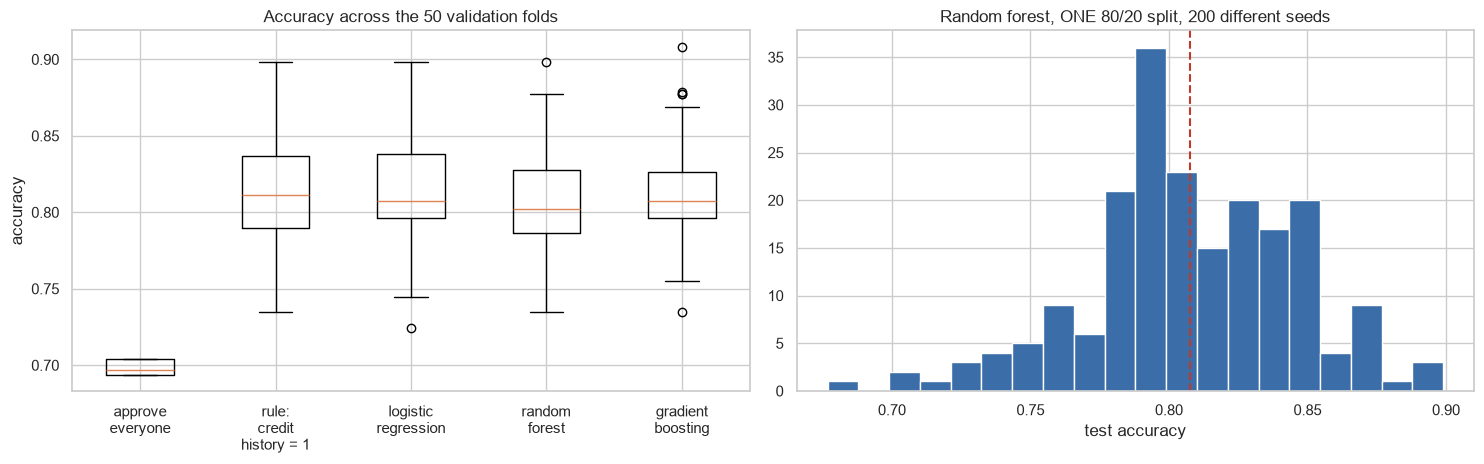

single-split accuracy over 200 seeds: min 0.677 | mean 0.808 | max 0.899 | 95% of splits fall in [0.727, 0.869]


In [6]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.8))
ax[0].boxplot([folds[k] for k in models], tick_labels=[k.replace(": ", ":\n").replace(" ", "\n", 1) for k in models], vert=True)
ax[0].set_title("Accuracy across the 50 validation folds"); ax[0].set_ylabel("accuracy")
# the reference's way: ONE random 80/20 split -> how far can the number move?
accs = []
for seed in range(200):
    Xa, Xb, ya, yb = train_test_split(X, y, test_size=.2, random_state=seed)
    accs.append(accuracy_score(yb, models["random forest"].fit(Xa, ya).predict(Xb)))
ax[1].hist(accs, bins=20, color="#3b6ea8"); ax[1].axvline(np.mean(accs), color="#c0392b", ls="--")
ax[1].set_title("Random forest, ONE 80/20 split, 200 different seeds"); ax[1].set_xlabel("test accuracy")
plt.tight_layout(); plt.show()
print("single-split accuracy over 200 seeds: min %.3f | mean %.3f | max %.3f | 95%% of splits fall in [%.3f, %.3f]" % (min(accs), np.mean(accs), max(accs), *np.percentile(accs, [2.5, 97.5])))

**Reading it.**
* **The one-line rule "approve if credit history = 1" is as accurate as every model: 81.3% vs 81.3% (logistic), 80.9% (forest), 81.2% (boosting).** The learned models add no accuracy over the rule.
* They do add *ranking* ability: ROC-AUC 0.70 for the rule (it can only output two scores) vs 0.76-0.77 for the models, i.e. the models separate applicants within the "credit history = 1" group somewhat better than chance.
* The spread across folds is about 3.3 percentage points, so differences of a few tenths of a point between models are not meaningful.
* **The reference's way of reporting (one 80/20 split) is fragile:** the same random forest scored anywhere from 67.7% to 89.9% depending only on the random seed (95% of splits between 72.7% and 86.9%). One reported accuracy on 491 rows carries an uncertainty of roughly +/-7 points.

## 5. Which applicants does the model get wrong, and what does a wrong approval cost?
Out-of-fold probabilities from the logistic model (every row is predicted by a model that never saw it). The **cost ratio is an assumption**: I assume approving a loan that should have been refused costs 3 times as much as refusing a good applicant. Change `COST_BAD_APPROVAL` to see the effect.

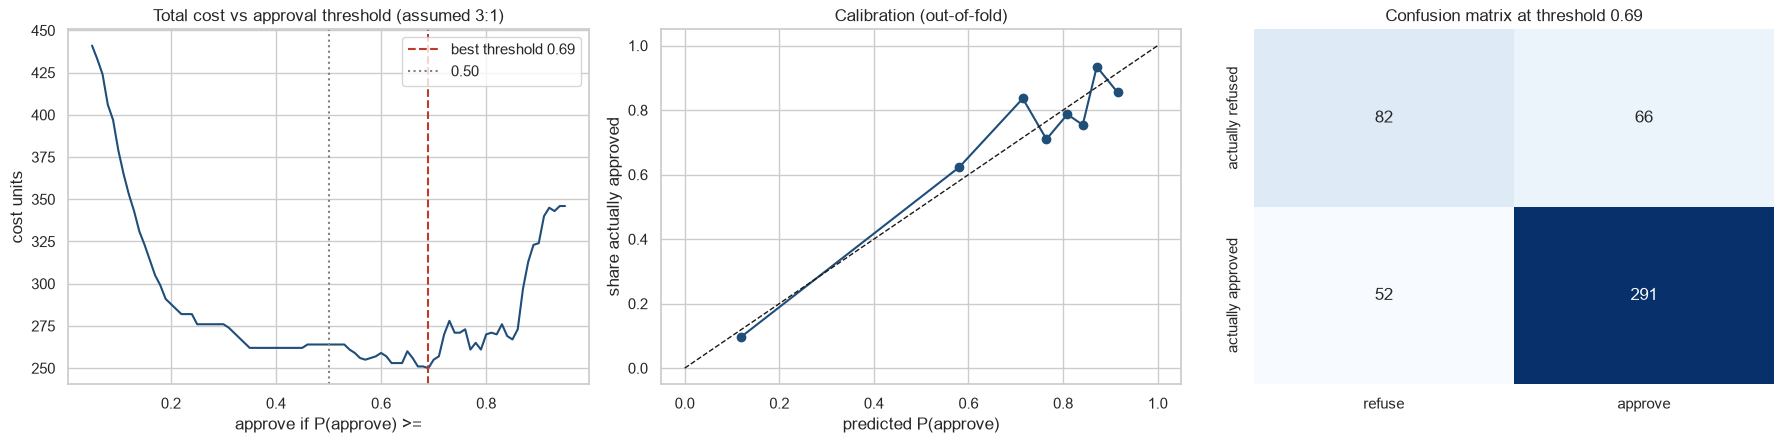

Brier score 0.152 | ROC-AUC 0.749 | accuracy at 0.50: 0.809 | at best threshold: 0.760
cost at 0.50: 264 | at best threshold: 250 | approve-everyone: 444


In [7]:
best_name = "logistic regression"
oof = cross_val_predict(models[best_name], X, y, cv=StratifiedKFold(5, shuffle=True, random_state=1), method="predict_proba")[:, 1]
COST_BAD_APPROVAL, COST_GOOD_REFUSAL = 3.0, 1.0
ths = np.linspace(.05, .95, 91)
cost = [COST_BAD_APPROVAL * ((oof >= t) & (y == 0)).sum() + COST_GOOD_REFUSAL * ((oof < t) & (y == 1)).sum() for t in ths]
t_best = float(ths[int(np.argmin(cost))])
fig, ax = plt.subplots(1, 3, figsize=(18, 4.6))
ax[0].plot(ths, cost, color="#1f4e79"); ax[0].axvline(t_best, color="#c0392b", ls="--", label=f"best threshold {t_best:.2f}"); ax[0].axvline(.5, color="gray", ls=":", label="0.50"); ax[0].legend()
ax[0].set_title("Total cost vs approval threshold (assumed 3:1)"); ax[0].set_xlabel("approve if P(approve) >="); ax[0].set_ylabel("cost units")
fp, mp = calibration_curve(y, oof, n_bins=8, strategy="quantile"); ax[1].plot(mp, fp, "o-", color="#1f4e79"); ax[1].plot([0, 1], [0, 1], "k--", lw=1)
ax[1].set_title("Calibration (out-of-fold)"); ax[1].set_xlabel("predicted P(approve)"); ax[1].set_ylabel("share actually approved")
for t, lab, col in [(.5, "threshold 0.50", "#9db8d6"), (t_best, f"threshold {t_best:.2f}", "#1f4e79")]:
    pass
cm = confusion_matrix(y, oof >= t_best); sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax[2], xticklabels=["refuse", "approve"], yticklabels=["actually refused", "actually approved"])
ax[2].set_title(f"Confusion matrix at threshold {t_best:.2f}"); plt.tight_layout(); plt.show()
print("Brier score %.3f | ROC-AUC %.3f | accuracy at 0.50: %.3f | at best threshold: %.3f" % (brier_score_loss(y, oof), roc_auc_score(y, oof), accuracy_score(y, oof >= .5), accuracy_score(y, oof >= t_best)))
print("cost at 0.50: %.0f | at best threshold: %.0f | approve-everyone: %.0f" % (cost[int(np.argmin(abs(ths - .5)))], min(cost), COST_BAD_APPROVAL * (y == 0).sum()))

**Reading it.**
* Under my *assumed* 3:1 cost ratio the best threshold is 0.69 (stricter than 0.50): cost 250 vs 264 at 0.50 and 444 for approving everyone. But the cost curve is nearly flat between about 0.3 and 0.7, so the threshold is not sharply determined; and it was chosen on the same out-of-fold predictions it is scored on, so the 14-unit saving is optimistic.
* At 0.69 the confusion matrix shows 66 bad approvals (of 148 applicants who were actually refused: 45% still approved) and 52 good applicants refused. Accuracy drops to 76% because the threshold now trades accuracy for fewer costly approvals.
* Calibration is roughly along the diagonal with noise, especially at the top where few cases fall in each bin (Brier 0.152). The probabilities are usable as rough guides, not precise.
* The real cost ratio of a lender is a business input; replace the 3:1 assumption with theirs.

## 6. A responsible-use check: do decisions differ between applicant groups?
The data contains `Gender` and `Married`. I compare the **historical** approval rate with the **model's** approval rate by group. A difference is a prompt to ask questions (does it come from credit history or income, or from the group itself?), not proof of unfairness or of fairness. Group sizes are small, so intervals are wide.

In [8]:
pred = oof >= t_best
rows = []
for c in ["Gender", "Married", "Education"]:
    for g, idx in df.groupby(c).groups.items():
        k = len(idx); rate = y.loc[idx].mean(); mrate = pred[df.index.get_indexer(idx)].mean()
        se = np.sqrt(rate * (1 - rate) / k)
        rows.append([c, g, k, rate, 1.96 * se, mrate])
fair = pd.DataFrame(rows, columns=["attribute", "group", "n", "historical_approval", "ci95_halfwidth", "model_approval"])
print(fair.round(3).to_string(index=False))
# is the gap explained by credit history?
print("\nshare with credit history = 1:", df.groupby("Married").Credit_History.mean().round(3).to_dict(), "(by Married)")

attribute        group   n  historical_approval  ci95_halfwidth  model_approval
   Gender       Female  88                0.625           0.101           0.591
   Gender         Male 393                0.715           0.045           0.756
  Married           No 166                0.614           0.074           0.542
  Married          Yes 324                0.741           0.048           0.821
Education     Graduate 388                0.716           0.045           0.768
Education Not Graduate 103                0.631           0.093           0.573

share with credit history = 1: {'No': 0.833, 'Yes': 0.856} (by Married)


**Reading it.** The model's approval rates differ more between groups than the historical rates do: e.g. married applicants 74% historically vs 82% by the model, unmarried 61% vs 54%; female 63% vs 59%, male 72% vs 76%. The model uses these columns as inputs, so it can amplify patterns in past decisions. Credit history does not explain the Married gap (credit-history = 1 for 85.6% of married and 83.3% of unmarried applicants). With 88 women and 166 unmarried applicants the intervals are wide (+/-7 to +/-10 points), so I do not claim a proven effect, but in any real lending use `Gender` and `Married` should be excluded and the decision rule audited, and legal requirements checked. This is a screening exercise, not compliance advice.

## 7. Final model and save

In [9]:
final = models["logistic regression"].fit(X, y)
joblib.dump(final, "model/loan_logreg.joblib")
joblib.dump(models["random forest"].fit(X, y), "model/loan_rf.joblib")
meta = {"features_raw": list(X.columns), "cat_values": {c: sorted(df[c].dropna().astype(str).unique().tolist()) for c in cat},
        "ranges": {c: [float(df[c].min()), float(df[c].max())] for c in ["ApplicantIncome", "CoapplicantIncome", "LoanAmount", "Loan_Amount_Term"]},
        "threshold": t_best, "cv": res.round(3).to_dict("index")}
json.dump(meta, open("model/meta.json", "w"), indent=1); print(os.listdir("model"))

['loan_logreg.joblib', 'loan_rf.joblib', 'meta.json']


## 8. Summary: my approach vs the reference
| | Reference | This notebook |
|---|---|---|
| Evaluation | one random 80/20 split | 5-fold CV x 10 repeats; plus 200 single-split seeds to show the instability |
| Baselines | none | approve-everyone (69.9%); credit-history rule (81.3%) |
| Result | random forest accuracy (one number) | **all models about 81%; the one-line rule matches them**; models add AUC (0.70 -> 0.77) |
| Decision | accuracy | cost-aware threshold (assumed 3:1), calibration, confusion matrix |
| Responsible use | not covered | group approval rates, model vs history |

**What I learned.** (1) Always benchmark against the simplest rule an analyst would write: here it equals the ML models in accuracy. (2) On a few hundred rows a single split can mislead by +/-7 points. (3) Picking a threshold needs a stated cost assumption, and the result is often flat. (4) Check group differences before deploying anything that decides about people.

**Limits.** 491 labelled rows (reference 614); no repayment outcomes, only past approvals; the 3:1 cost is assumed; one lender's decisions. **Next step:** repayment data to model default risk instead of approval, and a proper fairness audit with legal input.